## Dwell time optimization via TG-43 2D formalism

This notebook sets up an end-to-end model to run optimization over dwell times via the general TG-43 2D formalism, defined in Rivard et al. (2004) as:

$$ \dot{D}(r, \theta) = S_K \cdot \Lambda \cdot \frac{G_L(r, \theta)}{G_L(r_0, \theta_0)} \cdot g_L(r) \cdot F(r, \theta) $$

We define functions that allow for interpolation of $g_L(r)$ and $F(r, \theta)$ between tabulated values. We also define a function that calculates the value of $G_L(r, \theta)$ for a given dose point at position $(r, \theta)$. These calculations are combined to compute $\dot{D}(r, \theta)$; the dose rate values are then fed into a linear penalty model which outputs an optimal distribution of dwell times over dwell positions.

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy.optimize import curve_fit
from scipy.interpolate import RegularGridInterpolator

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

### Step 1 - generate dose points

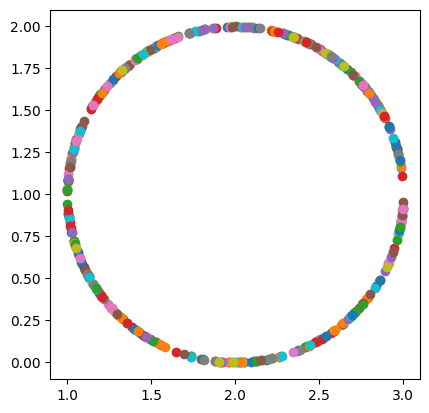

In [2]:
# To maintain consistency with the previously defined 3D model that uses TOPAS simulations to calculate dose rate,
# we'll select our dose points from the uniform distribution on a unit circle centered at (X, Z) = (2, 1).
num_points = 500
origin = (2,1)
dose_points = generate_points_uniform_circle(num_points, origin=origin)

# sanity check that we're getting a circle!
fig, ax = plt.subplots()
ax.set_aspect('equal')
for p in dose_points:
    ax.scatter(p[0], p[1])
plt.show()

## NOTE - this cell only needs to be run ONCE - otherwise you'll have a new random set of dose points 
## for each run of this notebook. After running this cell, comment out the function below.
#np.save("dose_points_2D", dose_points)

### Step 2 - compute dose point location relative to source

In [13]:
# load the dose points from a saved .npy file - this ensures the dose points stay constant
dose_points = np.load("dose_points_2D.npy")

In [25]:
# since the dose points are in cartesian coords, it's straightforward to compute (r, theta) w/respect to source center
# this is where the dwell positions come into the optimization!
# we assume the source is at (X,Y) = (0,0), but the Z coordinate will change with the dwell position
# for initial model, let's assume 1 mm spacing from -25 mm to 25 mm
dwell_start = -25 # mm
dwell_end = 25 # mm
spacing = 1 # mm
source_transZ = np.array([x for x in range(dwell_start, dwell_end + 1, spacing)])/10 # divide by 10 to convert mm --> cm

source_centers = []
for z in source_transZ:
    source_centers.append((0, z)) # note that we're operating in the Y = 0 plane (2D formalism)
source_centers = np.array(source_centers)

# rows = ith dwell position, columns = jth dose point
relative_dose_loc = np.empty((len(source_centers), len(dose_points)), dtype=object)
for i, dwell in enumerate(source_centers):

    for j, dose in enumerate(dose_points):
        r = np.sqrt( (dwell[0] - dose[0])**2 + (dwell[1] - dose[1])**2 )
        #theta = 

        relative_dose_loc[i][j] = (r, theta)

(np.float64(5.007172857879668), 0)
